# Qwen3.8 on ARC: A100 development pilot

On November 8, 2026, Qwen3.8-27B FP8 generated two candidates for each of three development tasks on a Colab A100 40 GB GPU. **All three workers completed; all 6/6 candidates failed the strict output-format check.** No answer accuracy was measured.

This is a small development pilot, not the 200-task Phase A evaluation or an ARC-AGI-2 benchmark score. It shows that the model and execution path ran, while highlighting an output-format problem.

## Experiment and evidence

- Model: `Qwen/Qwen3.8-27B-FP8`, revision `c3a462cc3d38cf351f3b26cbd763469eeb74ef81`; vLLM 0.33.0, A100 40 GB, context 18,432 tokens, up to 4,096 output tokens per candidate.
- Registered code: [`cbba28c04dfa28fb900b92087e6fd5214da7e6b3`](https://github.com/morshoto/qwen-meetup-2/tree/cbba28c04dfa28fb900b92087e6fd5214da7e6b3); [pilot notebook and PR](https://github.com/morshoto/qwen-meetup-2/pull/15).
- Three task result files were retrieved from `MyDrive/qwen-colab/runs/validation-20261108-cbba28c/single/` and are identified by SHA-256 below. The Drive path is private to the account and is not needed to run this notebook.
- This report embeds aggregates from those result files; it does not load model outputs, run inference, read held-out answers, or score correctness. Worker completion means the process finished, not that its answers were valid.

| Task | Result file SHA-256 |
|---|---|
| `84db8fc4` | `6a80095bdb7bf5c25f4375f2a9cd38f3a9181a1cc1db6e6d777f0c767471740b` |
| `a64e4611` | `819fbdddc84c64b0ed1d62f5146e01a56850afdfcbd622920fb30aa82189902a` |
| `e5c44e8f` | `0c834be85adb6281c541fee117d2c1031aeb2010eb269cf78c8ce014efe219d1` |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Embedded from the three saved development-pilot result records.
records = [{'task_id': '84db8fc4', 'worker_status': 'complete', 'generation_seconds': 55.065, 'worker_seconds': 122.015, 'prompt_tokens': 1923, 'candidates': [{'candidate': 0, 'valid': False, 'completion_tokens': 209, 'finish_reason': 'stop', 'error': 'output count does not match test inputs'}, {'candidate': 1, 'valid': False, 'completion_tokens': 202, 'finish_reason': 'stop', 'error': 'output count does not match test inputs'}]}, {'task_id': 'a64e4611', 'worker_status': 'complete', 'generation_seconds': 242.128, 'worker_seconds': 308.449, 'prompt_tokens': 12715, 'candidates': [{'candidate': 0, 'valid': False, 'completion_tokens': 2, 'finish_reason': 'stop', 'error': 'output count does not match test inputs'}, {'candidate': 1, 'valid': False, 'completion_tokens': 1804, 'finish_reason': 'stop', 'error': 'output count does not match test inputs'}]}, {'task_id': 'e5c44e8f', 'worker_status': 'complete', 'generation_seconds': 66.7, 'worker_seconds': 132.773, 'prompt_tokens': 1809, 'candidates': [{'candidate': 0, 'valid': False, 'completion_tokens': 251, 'finish_reason': 'stop', 'error': 'output count does not match test inputs'}, {'candidate': 1, 'valid': False, 'completion_tokens': 251, 'finish_reason': 'stop', 'error': 'output count does not match test inputs'}]}]
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

## Execution and format validity

The strict parser reported “output count does not match test inputs” for every candidate. These invalid outputs are not correct answers, but they have not been scored against solutions either. The denominator is exactly six generated candidates across three tasks.

In [2]:
candidates = pd.DataFrame([
    {"task": r["task_id"], **c} for r in records for c in r["candidates"]
])
display(candidates[["task", "candidate", "valid", "completion_tokens", "finish_reason", "error"]].rename(columns={"valid": "format valid"}))
print(f"Workers completed: {sum(r['worker_status'] == 'complete' for r in records)}/{len(records)}")
print(f"Format-valid candidates: {int(candidates['valid'].sum())}/{len(candidates)}")
print("Correctness: not scored")

,task,candidate,format valid,completion_tokens,finish_reason,error
0,84db8fc4,0,False,209,stop,output count does not match test inputs
1,84db8fc4,1,False,202,stop,output count does not match test inputs
2,a64e4611,0,False,2,stop,output count does not match test inputs
3,a64e4611,1,False,1804,stop,output count does not match test inputs
4,e5c44e8f,0,False,251,stop,output count does not match test inputs
5,e5c44e8f,1,False,251,stop,output count does not match test inputs


Workers completed: 3/3
Format-valid candidates: 0/6
Correctness: not scored


## Time per task

Generation time is the recorded inference time for both candidates. Worker time includes model startup, generation, and cleanup. It excludes the separate model-inventory and registration checks and is **not** the complete end-to-end runtime or a price estimate. Each task launched a separate worker and reloaded the model.

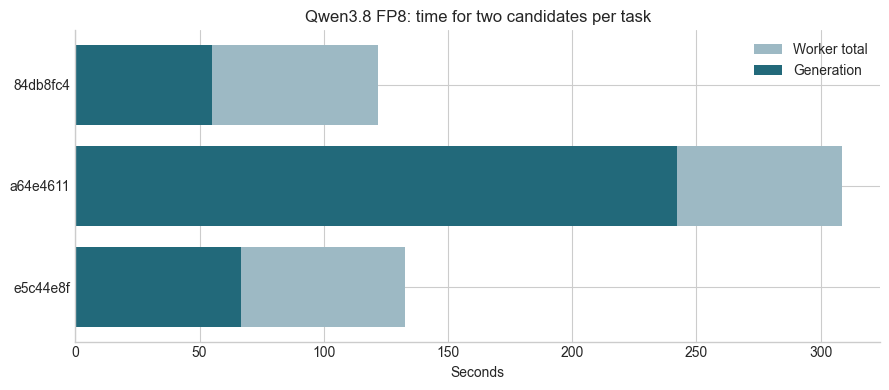

,task,worker_status,generation_seconds,worker_seconds,input tokens
0,84db8fc4,complete,55.1,122.0,1923
1,a64e4611,complete,242.1,308.4,12715
2,e5c44e8f,complete,66.7,132.8,1809


In [3]:
tasks = pd.DataFrame(records).drop(columns="candidates")
fig, ax = plt.subplots()
y = range(len(tasks))
ax.barh(y, tasks["worker_seconds"], color="#9db9c4", label="Worker total")
ax.barh(y, tasks["generation_seconds"], color="#22697a", label="Generation")
ax.set_yticks(list(y), tasks["task_id"])
ax.invert_yaxis()
ax.set(xlabel="Seconds", title="Qwen3.8 FP8: time for two candidates per task")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
display(tasks.rename(columns={"task_id": "task", "prompt_tokens": "input tokens"}).round(1))

## What this tells us

- The A100 ran Qwen3.8 FP8 on all three registered tasks and wrote result records to Drive. A local replay of downloaded journal records found no pending tasks; disconnect-and-resume on Colab was not tested.
- The longest input was 12,715 tokens, within the configured context when reserving 4,096 output tokens. Longer context did not resolve the output-format failures.
- Three tasks are too few to estimate accuracy or reliably project the cost of 200 tasks. The input lengths and output lengths differ considerably, and full-run overhead includes additional checks.
- Before a larger evaluation, investigate why the model returns the wrong number of output grids and validate a change on development tasks. Keep any scoring and the separately gated Phase A run distinct from this pilot.